# Reinforcement Learning (Q-Learning)
**Part A:** Maze  |  **Part B:** Taxi problem  |  **Part C:** Tic-Tac-Toe

All three use **Q-learning**: the agent keeps a table `Q(state, action)` and updates it after every step with

`Q(s,a) ← Q(s,a) + α [ r + γ · max Q(s',a') − Q(s,a) ]`

Actions are chosen with an ε-greedy policy (mostly the best known action, sometimes a random one to explore).

In [1]:
%pip install -q gymnasium

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from collections import defaultdict

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(42)

def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode="valid")

## Part A: Maze Environment
The agent starts at the top-left corner and must reach the goal at the bottom-right. Rewards: **−1** per move, **−5** for bumping into a wall or the edge, **+100** for reaching the goal.

In [3]:
maze = np.array([[0, 0, 0, 1, 0, 0],      # 1 = wall
                 [1, 1, 0, 1, 0, 1],
                 [0, 0, 0, 0, 0, 0],
                 [0, 1, 1, 1, 1, 0],
                 [0, 0, 0, 0, 1, 0],
                 [1, 1, 1, 0, 0, 0]])
START, GOAL = (0, 0), (5, 5)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]      # up, down, left, right
n = maze.shape[0]

def maze_step(state, a):
    r, c = state[0] + MOVES[a][0], state[1] + MOVES[a][1]
    if not (0 <= r < n and 0 <= c < n) or maze[r, c] == 1:
        return state, -5, False                  # hit a wall: stay in place
    return (r, c), (100 if (r, c) == GOAL else -1), (r, c) == GOAL

Learned path length: 10 steps  |  reached goal: True


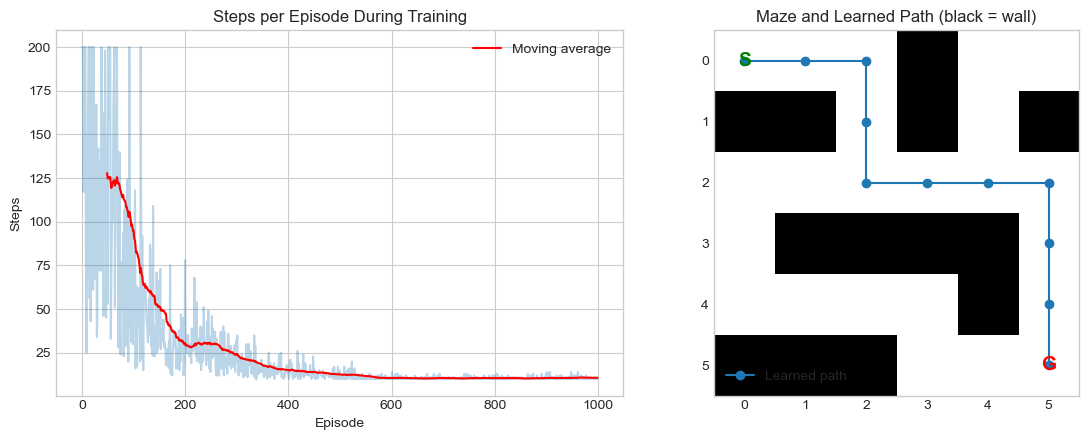

In [4]:
Q = np.zeros((n, n, 4))
alpha, gamma, episodes = 0.1, 0.95, 1000
steps_per_episode = []

for ep in range(episodes):
    eps = max(0.05, 1 - ep / (0.6 * episodes))               # exploration decays over time
    state, done, steps = START, False, 0
    while not done and steps < 200:
        a = rng.integers(4) if rng.random() < eps else Q[state].argmax()
        nxt, reward, done = maze_step(state, a)
        Q[state][a] += alpha * (reward + gamma * Q[nxt].max() * (not done) - Q[state][a])
        state, steps = nxt, steps + 1
    steps_per_episode.append(steps)

# Follow the learned (greedy) policy
state, path = START, [START]
while state != GOAL and len(path) < 50:
    state, _, _ = maze_step(state, Q[state].argmax())
    path.append(state)
print(f"Learned path length: {len(path) - 1} steps  |  reached goal: {state == GOAL}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(steps_per_episode, alpha=0.3)
ax[0].plot(range(49, episodes), moving_avg(steps_per_episode), color="red", label="Moving average")
ax[0].set(title="Steps per Episode During Training", xlabel="Episode", ylabel="Steps"); ax[0].legend()

ax[1].imshow(maze, cmap="Greys"); ax[1].grid(False)
ax[1].plot(*zip(*[(c, r) for r, c in path]), "o-", color="tab:blue", label="Learned path")
ax[1].text(START[1], START[0], "S", color="green", ha="center", va="center", fontsize=14, fontweight="bold")
ax[1].text(GOAL[1], GOAL[0], "G", color="red", ha="center", va="center", fontsize=14, fontweight="bold")
ax[1].set(title="Maze and Learned Path (black = wall)"); ax[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Result:** the number of steps per episode falls quickly as the agent learns, and the final policy follows a short path from the start to the goal.

## Part B: Taxi Problem
Gymnasium's `Taxi` environment (v3 / v4): the taxi must go to the passenger, pick them up, drive to the destination and drop them off. Rewards: **−1** per step, **+20** for a correct drop-off, **−10** for an illegal pickup or drop-off. The environment has 500 states and 6 actions (4 moves, pickup, drop-off).

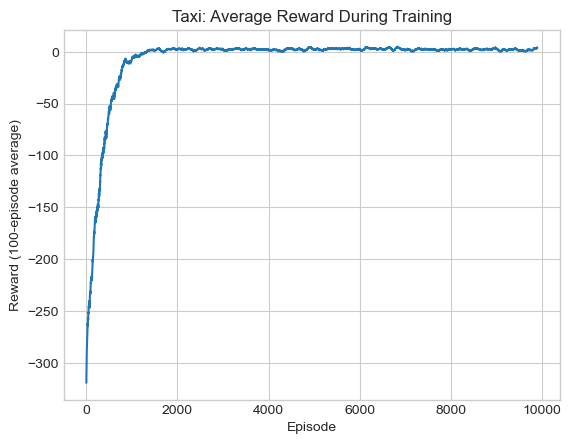

In [5]:
try:
    env = gym.make("Taxi-v4")      # newer Gymnasium versions
except Exception:
    env = gym.make("Taxi-v3")      # older versions
Qt = np.zeros((env.observation_space.n, env.action_space.n))
alpha, gamma, eps, episodes = 0.1, 0.99, 0.1, 10000
train_rewards = []

for ep in range(episodes):
    s, _ = env.reset()
    done, total = False, 0
    while not done:
        a = env.action_space.sample() if rng.random() < eps else Qt[s].argmax()
        s2, r, terminated, truncated, _ = env.step(a)
        done = terminated or truncated
        Qt[s, a] += alpha * (r + gamma * Qt[s2].max() * (not terminated) - Qt[s, a])
        s, total = s2, total + r
    train_rewards.append(total)

plt.plot(moving_avg(train_rewards, 100))
plt.title("Taxi: Average Reward During Training"); plt.xlabel("Episode"); plt.ylabel("Reward (100-episode average)")
plt.show()

**Test** the trained agent against a random agent over 100 episodes each.

In [6]:
def evaluate(policy, games=100):
    rewards, steps = [], []
    for _ in range(games):
        s, _ = env.reset()
        done, total, n_steps = False, 0, 0
        while not done:
            s, r, terminated, truncated, _ = env.step(policy(s))
            done, total, n_steps = terminated or truncated, total + r, n_steps + 1
        rewards.append(total); steps.append(n_steps)
    return np.mean(rewards), np.mean(steps)

for name, policy in [("Random agent ", lambda s: env.action_space.sample()), ("Q-learning   ", lambda s: Qt[s].argmax())]:
    r, st = evaluate(policy)
    print(f"{name}: average reward = {r:8.1f}  |  average steps = {st:6.1f}")

Random agent : average reward =   -751.8  |  average steps =  192.9
Q-learning   : average reward =      7.7  |  average steps =   13.3


**Result:** the random agent wanders and collects large penalties, while the trained agent picks up and drops off the passenger in about 13 steps with a positive reward.

## Part C: Tic-Tac-Toe
**a. Environment:** the board is a list of 9 cells (0 = empty, 1 = agent 'X', −1 = opponent 'O'). The opponent plays random moves.  
**b. Game rules:** three in a row wins; a full board is a draw.  
**c. Model:** Q-table over (board state, move). Rewards: **+1** win, **−1** loss, **+0.5** draw, 0 otherwise.

In [7]:
LINES = [(0,1,2), (3,4,5), (6,7,8), (0,3,6), (1,4,7), (2,5,8), (0,4,8), (2,4,6)]

def free(b):
    return [i for i in range(9) if b[i] == 0]

def result(b):
    """1 = agent wins, -1 = opponent wins, 0 = draw, None = game continues."""
    for i, j, k in LINES:
        if b[i] != 0 and b[i] == b[j] == b[k]:
            return b[i]
    return None if free(b) else 0

REWARD = {1: 1, -1: -1, 0: 0.5, None: 0}
Q3 = defaultdict(lambda: np.zeros(9))

def play_game(eps, learn, alpha=0.3, gamma=0.9):
    """Play one game (agent X vs random O). Returns 1 (win), -1 (loss) or 0 (draw)."""
    b = [0] * 9
    if rng.random() < 0.5:                                  # opponent starts half the time
        b[rng.choice(free(b))] = -1
    while True:
        s, moves = tuple(b), free(b)
        a = rng.choice(moves) if rng.random() < eps else max(moves, key=lambda m: Q3[s][m])
        b[a] = 1
        res = result(b)
        if res is None:                                     # opponent replies with a random move
            b[rng.choice(free(b))] = -1
            res = result(b)
        if learn:
            nxt = tuple(b)
            future = 0 if res is not None else max(Q3[nxt][m] for m in free(b))
            Q3[s][a] += alpha * (REWARD[res] + gamma * future - Q3[s][a])
        if res is not None:
            return res

**d. Training** — 30,000 games against the random opponent, with ε decaying from 1 to 0.05.

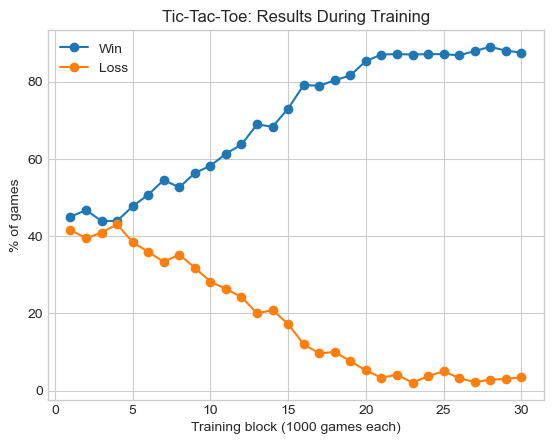

States learned: 4428


In [8]:
games = 30000
outcomes = []
for g in range(games):
    outcomes.append(play_game(eps=max(0.05, 1 - g / (0.7 * games)), learn=True))

outcomes = np.array(outcomes).reshape(-1, 1000)               # 30 blocks of 1000 games
plt.plot(range(1, 31), (outcomes == 1).mean(axis=1) * 100, marker="o", label="Win")
plt.plot(range(1, 31), (outcomes == -1).mean(axis=1) * 100, marker="o", label="Loss")
plt.title("Tic-Tac-Toe: Results During Training"); plt.xlabel("Training block (1000 games each)"); plt.ylabel("% of games")
plt.legend()
plt.show()
print("States learned:", len(Q3))

**e. Testing** — 2,000 games with no exploration, compared with a random player (no learning) in the same position.

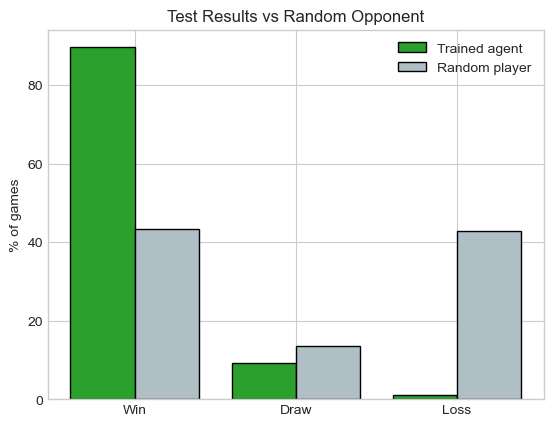

Trained agent : win 89.6%  draw 9.2%  loss 1.1%
Random player : win 43.5%  draw 13.6%  loss 43.0%


In [9]:
def test(eps, games=2000):
    res = np.array([play_game(eps=eps, learn=False) for _ in range(games)])
    return [(res == 1).mean() * 100, (res == 0).mean() * 100, (res == -1).mean() * 100]

trained, random_player = test(eps=0), test(eps=1)
x = np.arange(3)
plt.bar(x - 0.2, trained, 0.4, label="Trained agent", color="#2ca02c", edgecolor="black")
plt.bar(x + 0.2, random_player, 0.4, label="Random player", color="#b0bec5", edgecolor="black")
plt.xticks(x, ["Win", "Draw", "Loss"]); plt.ylabel("% of games"); plt.title("Test Results vs Random Opponent")
plt.legend()
plt.show()
print(f"Trained agent : win {trained[0]:.1f}%  draw {trained[1]:.1f}%  loss {trained[2]:.1f}%")
print(f"Random player : win {random_player[0]:.1f}%  draw {random_player[1]:.1f}%  loss {random_player[2]:.1f}%")

**Result:** the trained agent wins far more often than a random player. It was trained only against a random opponent, so it can still lose to a strong player; training it against itself (self-play) would make it stronger.